<a href="https://colab.research.google.com/github/anushkap0/RetinaScan-AI/blob/main/RetinaScanAI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, cv2
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (cohen_kappa_score, classification_report,
                              confusion_matrix, recall_score)
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/project/archive (12).zip'
extract_path = '/content/dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
print("Unzipped successfully!")

Unzipped successfully!


In [ ]:
DATA_DIR = r"/content/dataset/colored_images"

IMG_SIZE   = 224
BATCH      = 16
SEED       = 42
EPOCHS_P1  = 10
EPOCHS_P2  = 40

CLASS_NAMES = sorted([
    d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))
])
print('Classes found:', CLASS_NAMES)
assert len(CLASS_NAMES) == 5, f'Expected 5 classes, found {len(CLASS_NAMES)}. Check DATA_DIR path.'

Classes found: ['Mild', 'Moderate', 'No_DR', 'Proliferate_DR', 'Severe']


In [ ]:
!pip install opencv-python-headless -q


In [ ]:
# CELL 3 — Load paths + split
paths, labels = [], []
for idx, cls in enumerate(CLASS_NAMES):
    folder = Path(DATA_DIR) / cls
    for ext in ['*.jpg','*.jpeg','*.png','*.JPG','*.JPEG','*.PNG']:
        for f in folder.glob(ext):
            paths.append(str(f)); labels.append(idx)

paths  = np.array(paths)
labels = np.array(labels)

X_train, X_val, y_train, y_val = train_test_split(
    paths, labels, test_size=0.2,
    stratify=labels, random_state=SEED
)
print(f"Train: {len(X_train)} | Val: {len(X_val)}")

SAVE_DIR = '/content/drive/MyDrive/project/splits/'
os.makedirs(SAVE_DIR, exist_ok=True)
# Save the split so eval notebook uses EXACT same val set
np.save(SAVE_DIR + 'X_val.npy', X_val)
np.save(SAVE_DIR + 'y_val.npy', y_val)
np.save(SAVE_DIR + 'X_train.npy', X_train)
np.save(SAVE_DIR + 'y_train.npy', y_train)
print("✅ Splits saved to Drive")

Train: 2929 | Val: 733
✅ Splits saved to Drive


In [ ]:
# CELL 4 — Preprocessing
def crop_image_from_gray(img, tol=7):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > tol
    if img[np.ix_(mask.any(1), mask.any(0))].shape[0] == 0:
        return img
    r = img[:,:,0][np.ix_(mask.any(1), mask.any(0))]
    g = img[:,:,1][np.ix_(mask.any(1), mask.any(0))]
    b = img[:,:,2][np.ix_(mask.any(1), mask.any(0))]
    return np.stack([r,g,b], axis=-1)

def circle_crop(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL,
                                    cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return img
    cnt  = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(cnt)
    pad  = int(min(w,h)*0.02)
    x=max(0,x-pad); y=max(0,y-pad)
    w=min(img.shape[1]-x,w+2*pad); h=min(img.shape[0]-y,h+2*pad)
    return img[y:y+h, x:x+w]

def ben_graham_np(img_bytes, sigmaX=10, size=IMG_SIZE):
    try:
        nparr = np.frombuffer(img_bytes.numpy(), np.uint8)
        img   = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
        img   = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    except:
        return np.zeros((size,size,3), dtype=np.float32)
    if img is None or img.size == 0:
        return np.zeros((size,size,3), dtype=np.float32)
    img     = circle_crop(img)
    img     = crop_image_from_gray(img)
    img     = cv2.resize(img, (size,size))
    blurred = cv2.GaussianBlur(img, (0,0), sigmaX)
    img     = cv2.addWeighted(img, 4, blurred, -4, 128)
    img     = np.clip(img, 0, 255).astype(np.uint8)
    h, w    = img.shape[:2]
    circle  = np.zeros((h,w), np.uint8)
    cv2.circle(circle, (w//2,h//2), int(min(w,h)//2*0.9), 1, -1)
    img     = cv2.bitwise_and(img, img, mask=circle)
    return img.astype(np.float32) / 255.0

def load_img(path, label, augment=False):
    raw = tf.io.read_file(path)
    img = tf.py_function(func=lambda b: ben_graham_np(b),
                          inp=[raw], Tout=tf.float32)
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    if augment:
        img = tf.image.random_flip_left_right(img)
        img = tf.image.random_flip_up_down(img)
        img = tf.image.rot90(img, k=tf.random.uniform([],0,4,dtype=tf.int32))
        img = tf.image.random_brightness(img, 0.15)
        img = tf.image.random_contrast(img, 0.85, 1.15)
        img = tf.image.random_saturation(img, 0.8, 1.2)
    img   = img * 2.0 - 1.0
    label = tf.one_hot(label, len(CLASS_NAMES))
    return img, label

In [ ]:
# CELL 5 — Pipelines + class weights
train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(len(X_train), seed=SEED)
    .map(lambda x,y: load_img(x,y,augment=True),
         num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH).prefetch(tf.data.AUTOTUNE)
)
val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .map(lambda x,y: load_img(x,y,augment=False),
         num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH).prefetch(tf.data.AUTOTUNE)
)

# Verify
for imgs, lbls in val_ds.take(1):
    print(f"✅ Shape: {imgs.shape} | Range: [{imgs.numpy().min():.2f}, {imgs.numpy().max():.2f}]")

# Class weights with extra penalty on high-risk classes
raw_w = compute_class_weight('balanced',
        classes=np.unique(y_train), y=y_train)
class_weights = {i: min(float(w), 2.5) for i, w in enumerate(raw_w)}
for cls in ['Severe', 'Proliferate_DR']:
    if cls in CLASS_NAMES:
        idx = CLASS_NAMES.index(cls)
        class_weights[idx] = min(class_weights[idx]*1.5, 4.0)
print("Class weights:", class_weights)

✅ Shape: (16, 224, 224, 3) | Range: [-1.00, 1.00]
Class weights: {0: 1.979054054054054, 1: 0.7331664580725907, 2: 0.4056786703601108, 3: 3.7233050847457627, 4: 3.75}


In [ ]:
# CELL 6 — Focal + QWK combined loss
class FocalLoss(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=0.25, **kwargs):
        super().__init__(**kwargs)
        self.gamma = gamma; self.alpha = alpha
    def call(self, y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1-1e-7)
        ce     = -y_true * tf.math.log(y_pred)
        weight = self.alpha * y_true * tf.pow(1-y_pred, self.gamma)
        return tf.reduce_mean(tf.reduce_sum(weight*ce, axis=-1))

def qwk_loss(y_true, y_pred):
    num_classes = len(CLASS_NAMES)
    y_true_idx  = tf.cast(tf.argmax(y_true, axis=1), tf.float32)
    y_pred_idx  = tf.reduce_sum(
        y_pred * tf.cast(tf.range(num_classes), tf.float32), axis=1)
    weights = tf.square(y_true_idx - y_pred_idx) / tf.square(
        tf.cast(num_classes-1, tf.float32))
    return tf.reduce_mean(weights)

def combined_loss(y_true, y_pred):
    return 0.7*FocalLoss()(y_true,y_pred) + 0.3*qwk_loss(y_true,y_pred)

In [ ]:
def crop_image_from_gray(img, tol=7):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    mask = gray > tol
    if img[np.ix_(mask.any(1), mask.any(0))].shape[0] == 0:
        return img
    r = img[:,:,0][np.ix_(mask.any(1), mask.any(0))]
    g = img[:,:,1][np.ix_(mask.any(1), mask.any(0))]
    b = img[:,:,2][np.ix_(mask.any(1), mask.any(0))]
    return np.stack([r,g,b], axis=-1)

def circle_crop(img):
    """
    Step 1: Fit a circle to the retinal field and crop to it.
    This removes non-retinal borders BEFORE contrast enhancement,
    preventing the enhancement from amplifying border artifacts.
    """
    gray    = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    _, mask = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL,
                                    cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return img
    cnt  = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(cnt)
    # Add 2% padding
    pad  = int(min(w, h) * 0.02)
    x    = max(0, x - pad)
    y    = max(0, y - pad)
    w    = min(img.shape[1] - x, w + 2*pad)
    h    = min(img.shape[0] - y, h + 2*pad)
    return img[y:y+h, x:x+w]

def ben_graham_np(img_bytes, sigmaX=10, size=IMG_SIZE):
    """Circle crop FIRST, then Ben Graham contrast enhancement."""
    try:
        nparr = np.frombuffer(img_bytes.numpy(), np.uint8)
        img   = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
        img   = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    except:
        return np.zeros((size, size, 3), dtype=np.float32)
    if img is None or img.size == 0:
        return np.zeros((size, size, 3), dtype=np.float32)

    # Step 1: Circle crop (removes black border BEFORE enhancement)
    img     = circle_crop(img)
    img     = crop_image_from_gray(img)

    # Step 2: Resize
    img     = cv2.resize(img, (size, size))
    blurred = cv2.GaussianBlur(img, (0, 0), sigmaX)
    img     = cv2.addWeighted(img, 4, blurred, -4, 128)
    img     = np.clip(img, 0, 255).astype(np.uint8)

    # Step 4: Circular mask (clean up corners)
    h, w    = img.shape[:2]
    cx, cy  = w//2, h//2
    r       = int(min(cx, cy) * 0.9)
    circle  = np.zeros((h, w), np.uint8)
    cv2.circle(circle, (cx, cy), r, 1, thickness=-1)
    img     = cv2.bitwise_and(img, img, mask=circle)

    return img.astype(np.float32) / 255.0

def load_and_preprocess(path, label, augment=False):
    raw = tf.io.read_file(path)
    img = tf.py_function(func=lambda b: ben_graham_np(b),
                          inp=[raw], Tout=tf.float32)
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])

    if augment:
        img = tf.image.random_flip_left_right(img)
        img = tf.image.random_flip_up_down(img)
        img = tf.image.rot90(img, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
        img = tf.image.random_brightness(img, 0.15)
        img = tf.image.random_contrast(img, 0.85, 1.15)
        img = tf.image.random_saturation(img, 0.8, 1.2)

    img = img * 2.0 - 1.0
    return img, label

In [ ]:
def coral_loss(y_true, y_pred):
    """
    Consistent Rank Logits (CORAL) loss for ordinal classification.
    y_pred shape: (batch, NUM_CLASSES-1) — one logit per threshold
    y_true shape: (batch,) — integer class labels 0..4
    """
    num_thresholds = NUM_CLASSES - 1
    # Convert integer labels to ordinal binary matrix
    # e.g. label=2 → [1, 1, 0, 0] (rank >= 1, >= 2, NOT >=3, NOT >=4)
    y_true = tf.cast(y_true, tf.int32)
    ordinal = tf.TensorArray(tf.float32, size=num_thresholds)
    for k in range(num_thresholds):
        ordinal = ordinal.write(k, tf.cast(y_true > k, tf.float32))
    ordinal = tf.transpose(ordinal.stack())   # (batch, num_thresholds)

    loss = tf.nn.sigmoid_cross_entropy_with_logits(
        labels=ordinal, logits=y_pred
    )
    return tf.reduce_mean(loss)

def coral_predict(logits):
    """Convert CORAL logits → class label."""
    probs = tf.sigmoid(logits)                # (batch, 4)
    # Sum probabilities: label = number of thresholds exceeded
    labels = tf.reduce_sum(tf.cast(probs > 0.5, tf.int32), axis=1)
    return labels

# ── 4b. Focal Loss (handles class imbalance better than weighted CE) ──
# Focal loss down-weights easy examples so model focuses on hard minority cases

class FocalLoss(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=0.25, **kwargs):
        super().__init__(**kwargs)
        self.gamma = gamma
        self.alpha = alpha

    def call(self, y_true, y_pred):
        y_true    = tf.cast(y_true, tf.float32)
        y_pred    = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        ce        = -y_true * tf.math.log(y_pred)
        weight    = self.alpha * y_true * tf.pow(1 - y_pred, self.gamma)
        focal     = weight * ce
        return tf.reduce_mean(tf.reduce_sum(focal, axis=-1))

# ── 4c. QWK-aware Loss (optimizes for competition metric) ────────────
def qwk_loss(y_true, y_pred):
    """
    Soft approximation of Quadratic Weighted Kappa loss.
    Penalizes predictions proportional to squared distance from true label.
    """
    num_classes = NUM_CLASSES
    y_true_idx  = tf.cast(tf.argmax(y_true, axis=1), tf.float32)
    y_pred_idx  = tf.reduce_sum(
        y_pred * tf.cast(tf.range(num_classes), tf.float32), axis=1
    )
    weights = tf.square(y_true_idx - y_pred_idx) / tf.square(
        tf.cast(num_classes - 1, tf.float32)
    )
    return tf.reduce_mean(weights)

def combined_loss(y_true, y_pred):
    """Combine focal loss + QWK loss for best of both worlds."""
    fl  = FocalLoss(gamma=2.0, alpha=0.25)(y_true, y_pred)
    qwk = qwk_loss(y_true, y_pred)
    return 0.7 * fl + 0.3 * qwk

In [ ]:
NUM_CLASSES = len(CLASS_NAMES)

def make_one_hot(path, label, augment=False):
    img, lbl = load_and_preprocess(path, label, augment)
    return img, tf.one_hot(lbl, NUM_CLASSES)

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(len(X_train), seed=SEED)
    .map(lambda x, y: make_one_hot(x, y, augment=True),
         num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH)
    .prefetch(tf.data.AUTOTUNE)
)
val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .map(lambda x, y: make_one_hot(x, y, augment=False),
         num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH)
    .prefetch(tf.data.AUTOTUNE)
)
# Verify
for imgs, lbls in val_ds.take(1):
    print(f"✅ Batch: {imgs.shape} | Range: [{imgs.numpy().min():.2f}, {imgs.numpy().max():.2f}]")



✅ Batch: (16, 224, 224, 3) | Range: [-1.00, 1.00]


In [ ]:
# 6. CLASS WEIGHTS + FOCAL OVERSAMPLING
raw_w = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = {i: min(float(w), 3.0) for i, w in enumerate(raw_w)}
severe_idx      = CLASS_NAMES.index('Severe')
proliferate_idx = CLASS_NAMES.index('Proliferate_DR')
class_weights[severe_idx]      = min(class_weights[severe_idx] * 1.5, 4.0)
class_weights[proliferate_idx] = min(class_weights[proliferate_idx] * 1.5, 4.0)
print("Class weights:", class_weights)

Class weights: {0: 1.979054054054054, 1: 0.7331664580725907, 2: 0.4056786703601108, 3: 3.7233050847457627, 4: 4.0}


In [ ]:
# 7. MODEL — EfficientNetB4
base = tf.keras.applications.EfficientNetB4(
    weights='imagenet', include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base.trainable = False

inp = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x   = base(inp, training=False)
x   = tf.keras.layers.GlobalAveragePooling2D()(x)
x   = tf.keras.layers.BatchNormalization()(x)
x   = tf.keras.layers.Dense(512, activation='relu',
        kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
x   = tf.keras.layers.Dropout(0.5)(x)
x   = tf.keras.layers.Dense(256, activation='relu',
        kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
x   = tf.keras.layers.Dropout(0.3)(x)
out = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = tf.keras.Model(inp, out)
model.summary()

71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb4 (Functional)     │ (None, 7, 7, 1792)     │    17,673,823 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1792)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1792)           │         7,168 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       918,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,731,620 (71.46 MB)

 Trainable params: 1,054,213 (4.02 MB)

 Non-trainable params: 17,677,407 (67.43 MB)

In [ ]:
#8. PHASE 1 — Head warmup with combined loss
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=combined_loss,
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

print("\n=== PHASE 1: Head Warmup ===")
history_p1 = model.fit(
    train_ds, validation_data=val_ds,
    epochs=EPOCHS_P1,
    class_weight=class_weights,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', patience=5,
            restore_best_weights=True, min_delta=0.005
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_accuracy', factor=0.5,
            patience=3, min_lr=1e-6, verbose=1
        )
    ]
)


=== PHASE 1: Head Warmup ===
Epoch 1/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 733s 4s/step - accuracy: 0.4216 - auc: 0.7191 - loss: 0.4943 - val_accuracy: 0.4598 - val_auc: 0.7335 - val_loss: 0.3034 - learning_rate: 0.0010
Epoch 2/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 700s 4s/step - accuracy: 0.5039 - auc: 0.7675 - loss: 0.3160 - val_accuracy: 0.6085 - val_auc: 0.8049 - val_loss: 0.2823 - learning_rate: 0.0010
Epoch 3/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 691s 4s/step - accuracy: 0.5104 - auc: 0.7839 - loss: 0.2891 - val_accuracy: 0.6712 - val_auc: 0.8543 - val_loss: 0.2410 - learning_rate: 0.0010
Epoch 4/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 687s 4s/step - accuracy: 0.5323 - auc: 0.8049 - loss: 0.2715 - val_accuracy: 0.6808 - val_auc: 0.8496 - val_loss: 0.2324 - learning_rate: 0.0010
Epoch 5/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 695s 4s/step - accuracy: 0.5367 - auc: 0.8035 - loss: 0.2657 - val_accuracy: 0.6726 - val_auc: 0.8629 - val_loss: 0.2210 - learning_rate: 0.0010
Epoch 6/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 687s 

In [ ]:
print("\n=== PHASE 2: Fine-tuning ===")
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(2e-5),
    loss=combined_loss,
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

history_p2 = model.fit(
    train_ds, validation_data=val_ds,
    epochs=EPOCHS_P2,
    class_weight=class_weights,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=8,
            restore_best_weights=True, min_delta=0.001
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=4,
            min_lr=1e-8, verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            'retina_best_v3.keras',
            monitor='val_loss', save_best_only=True, mode='min'
        )
    ]
)


=== PHASE 2: Fine-tuning ===
Epoch 1/40
184/184 ━━━━━━━━━━━━━━━━━━━━ 843s 4s/step - accuracy: 0.5411 - auc: 0.7975 - loss: 0.2690 - val_accuracy: 0.6562 - val_auc: 0.8207 - val_loss: 0.2461 - learning_rate: 2.0000e-05
Epoch 2/40
184/184 ━━━━━━━━━━━━━━━━━━━━ 794s 4s/step - accuracy: 0.5490 - auc: 0.8090 - loss: 0.2641 - val_accuracy: 0.6671 - val_auc: 0.8399 - val_loss: 0.2311 - learning_rate: 2.0000e-05
Epoch 3/40
184/184 ━━━━━━━━━━━━━━━━━━━━ 808s 4s/step - accuracy: 0.5667 - auc: 0.8189 - loss: 0.2587 - val_accuracy: 0.6698 - val_auc: 0.8507 - val_loss: 0.2216 - learning_rate: 2.0000e-05
Epoch 4/40
184/184 ━━━━━━━━━━━━━━━━━━━━ 792s 4s/step - accuracy: 0.5654 - auc: 0.8217 - loss: 0.2555 - val_accuracy: 0.6685 - val_auc: 0.8480 - val_loss: 0.2237 - learning_rate: 2.0000e-05
Epoch 5/40
184/184 ━━━━━━━━━━━━━━━━━━━━ 801s 4s/step - accuracy: 0.5667 - auc: 0.8264 - loss: 0.2555 - val_accuracy: 0.6644 - val_auc: 0.8453 - val_loss: 0.2244 - learning_rate: 2.0000e-05
Epoch 6/40
184/184 ━━━━━━

In [ ]:
TTA_STEPS = 5 # Define TTA_STEPS before it's used

def tta_predict(model, val_ds, n_augments=TTA_STEPS):
    """
    Average predictions across multiple augmented versions of each image.
    Typically gives +1-3% accuracy with zero retraining.
    """
    print(f"\nRunning TTA with {n_augments} augmentations per image...")
    all_probs = []

    for _ in range(n_augments):
        batch_probs = []
        for imgs, _ in val_ds:
            # Apply random augmentation to val images
            aug_imgs = tf.map_fn(
                lambda img: tf.image.random_flip_left_right(
                    tf.image.random_flip_up_down(img)
                ), imgs
            )
            # Random 90-degree rotation
            k = tf.random.uniform([], 0, 4, dtype=tf.int32)
            aug_imgs = tf.map_fn(lambda img: tf.image.rot90(img, k=k), aug_imgs)
            probs = model.predict(aug_imgs, verbose=0)
            batch_probs.extend(probs)
        all_probs.append(batch_probs)

    # Average across all augmentations
    avg_probs = np.mean(all_probs, axis=0)
    return avg_probs

In [ ]:
UNCERTAINTY_THRESHOLD = 0.9 # Define uncertainty threshold


=== Standard Evaluation ===
Standard Accuracy: 68.89%
Standard Kappa:    0.1867

Running TTA with 5 augmentations per image...

TTA Accuracy:      69.30%  (+ 0.41% vs standard)
TTA Kappa:         0.1919

=== Per-Class Sensitivity (Recall) — TTA ===
HIGH SENSITIVITY on Severe/Proliferative is the clinical priority

  Mild                : 0.0% ⚠️  LOW — review model!
  Moderate            : 95.5% ✅
  No_DR               : 87.8% ✅
  Proliferate_DR      : 0.0% ⚠️  LOW — review model! [HIGH RISK CLASS]
  Severe              : 0.0% ⚠️  LOW — review model! [HIGH RISK CLASS]

Full Classification Report (TTA):
                precision    recall  f1-score   support

          Mild       0.00      0.00      0.00        74
      Moderate       0.48      0.95      0.64       200
         No_DR       0.95      0.88      0.91       361
Proliferate_DR       0.00      0.00      0.00        59
        Severe       0.00      0.00      0.00        39

      accuracy                           0.69      

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


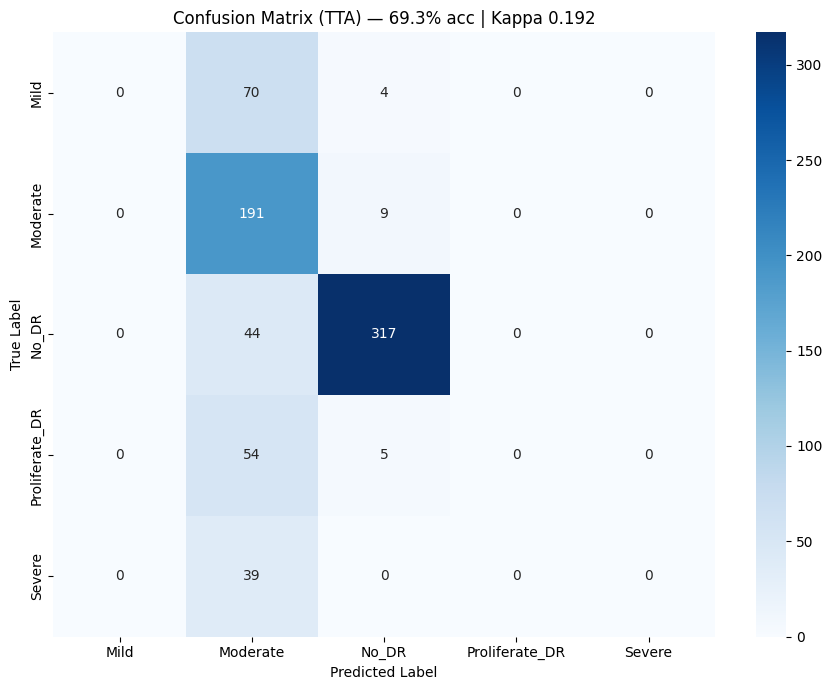


Standard: 68.89% acc | Kappa 0.1867
TTA:      69.30% acc | Kappa 0.1919
TTA gain: +0.41%


In [ ]:
# 11. EVALUATION — standard + TTA + per-class sensitivity
model = tf.keras.models.load_model(
    'retina_best_v3.keras',
    custom_objects={'combined_loss': combined_loss}
)

# Standard predictions
print("\n=== Standard Evaluation ===")
std_probs, all_true = [], []
for imgs, lbls in val_ds:
    probs = model.predict(imgs, verbose=0)
    std_probs.extend(probs)
    all_true.extend(np.argmax(lbls.numpy(), axis=1))

std_probs  = np.array(std_probs)
all_true   = np.array(all_true)
std_preds  = np.argmax(std_probs, axis=1)
std_acc    = np.mean(std_preds == all_true)
std_kappa  = cohen_kappa_score(all_true, std_preds, weights='quadratic')

print(f"Standard Accuracy: {std_acc*100:.2f}%")
print(f"Standard Kappa:    {std_kappa:.4f}")

# TTA predictions
tta_probs  = tta_predict(model, val_ds)
tta_preds  = np.argmax(tta_probs, axis=1)
tta_acc    = np.mean(tta_preds == all_true)
tta_kappa  = cohen_kappa_score(all_true, tta_preds, weights='quadratic')

print(f"\nTTA Accuracy:      {tta_acc*100:.2f}%  (+ {(tta_acc-std_acc)*100:.2f}% vs standard)")
print(f"TTA Kappa:         {tta_kappa:.4f}")
# ── Per-class sensitivity (recall) ─────────────────────────────────
# For a SCREENING TOOL, missing Severe/Proliferative is the worst outcome
print("\n=== Per-Class Sensitivity (Recall) — TTA ===")
print("HIGH SENSITIVITY on Severe/Proliferative is the clinical priority\n")
per_class_recall = recall_score(all_true, tta_preds, average=None)
for i, cls in enumerate(CLASS_NAMES):
    flag = " ⚠️  LOW — review model!" if per_class_recall[i] < 0.70 else " ✅"
    priority = " [HIGH RISK CLASS]" if cls in ['Severe', 'Proliferate_DR'] else ""
    print(f"  {cls:20s}: {per_class_recall[i]*100:.1f}%{flag}{priority}")

print("\nFull Classification Report (TTA):")
print(classification_report(all_true, tta_preds, target_names=CLASS_NAMES))

# ── Confusion matrix ────────────────────────────────────────────────
cm = confusion_matrix(all_true, tta_preds)
plt.figure(figsize=(9,7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f'Confusion Matrix (TTA) — {tta_acc*100:.1f}% acc | Kappa {tta_kappa:.3f}')
plt.ylabel('True Label'); plt.xlabel('Predicted Label')
plt.tight_layout(); plt.show()

# ── Standard vs TTA comparison ──────────────────────────────────────
print(f"\n{'='*50}")
print(f"Standard: {std_acc*100:.2f}% acc | Kappa {std_kappa:.4f}")
print(f"TTA:      {tta_acc*100:.2f}% acc | Kappa {tta_kappa:.4f}")
print(f"TTA gain: +{(tta_acc-std_acc)*100:.2f}%")
print(f"{'='*50}")


=== Uncertainty Analysis (threshold=0.9) ===
Total val samples:    733
Uncertain predictions: 705 (96.2%)
  → These would be flagged in the app for manual review

Accuracy on CERTAIN predictions:   100.00%
Accuracy on UNCERTAIN predictions: 68.09%
(Uncertain predictions should be referred to human review)


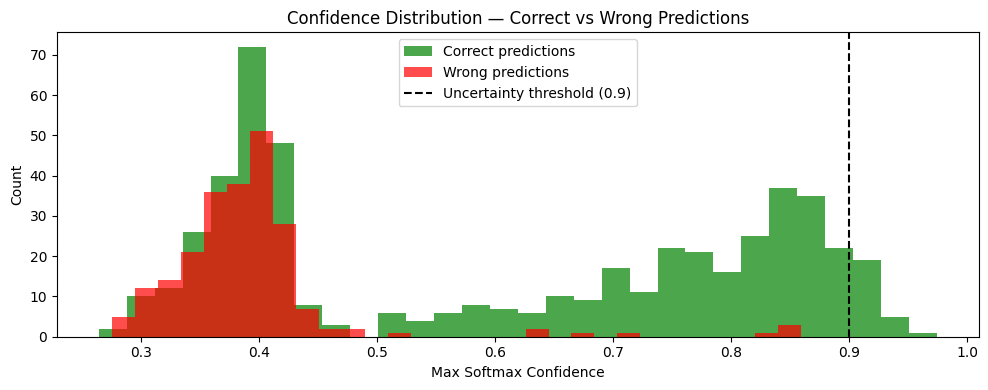

In [ ]:
#12 UNCERTAINTY FLAGGING
print(f"\n=== Uncertainty Analysis (threshold={UNCERTAINTY_THRESHOLD}) ===")
max_confidences = np.max(tta_probs, axis=1)
uncertain_mask  = max_confidences < UNCERTAINTY_THRESHOLD
n_uncertain     = np.sum(uncertain_mask)

print(f"Total val samples:    {len(all_true)}")
print(f"Uncertain predictions: {n_uncertain} ({n_uncertain/len(all_true)*100:.1f}%)")
print(f"  → These would be flagged in the app for manual review")

# Accuracy on certain vs uncertain predictions
certain_acc   = np.mean(tta_preds[~uncertain_mask] == all_true[~uncertain_mask])
uncertain_acc = np.mean(tta_preds[uncertain_mask]  == all_true[uncertain_mask]) if n_uncertain > 0 else 0
print(f"\nAccuracy on CERTAIN predictions:   {certain_acc*100:.2f}%")
print(f"Accuracy on UNCERTAIN predictions: {uncertain_acc*100:.2f}%")
print("(Uncertain predictions should be referred to human review)")

# Confidence distribution plot
plt.figure(figsize=(10, 4))
plt.hist(max_confidences[all_true == tta_preds],
         bins=30, alpha=0.7, color='green', label='Correct predictions')
plt.hist(max_confidences[all_true != tta_preds],
         bins=30, alpha=0.7, color='red', label='Wrong predictions')
plt.axvline(x=UNCERTAINTY_THRESHOLD, color='black', linestyle='--',
            label=f'Uncertainty threshold ({UNCERTAINTY_THRESHOLD})')
plt.xlabel('Max Softmax Confidence')
plt.ylabel('Count')
plt.title('Confidence Distribution — Correct vs Wrong Predictions')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
 #13. SAVE PROBABILITIES FOR ENSEMBLE
np.save('probs_efficientnetb4_tta.npy', tta_probs)
np.save('val_true_labels.npy', all_true)
print("\nSaved: probs_efficientnetb4_tta.npy")
print("Saved: val_true_labels.npy")
print("Use these in the ensemble notebook.")


Saved: probs_efficientnetb4_tta.npy
Saved: val_true_labels.npy
Use these in the ensemble notebook.
